# Task 02 — Analyze Data Using Python

**Objective:** Analyze the Titanic dataset using Python, Pandas, and NumPy to discover useful statistics, patterns, trends, and relationships between variables.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Analysis Includes:**
- Basic statistical analysis
- Highest and lowest values
- Group-wise comparisons
- Survival trends
- Relationships between relevant columns
- Data visualizations
- At least three important findings

IMPORT LIBRARIES

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

LOAD DATASET

In [19]:
df = pd.read_csv("titanic_cleaned.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


DATASET OVERVIEW

In [20]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 11)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 111.0 KB


CHECK MISSING VALUES AND DUPLICATE

In [21]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Duplicate Rows: 0


BASIC STATISTIC

In [22]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


STATISTICS USING NUMPY

In [23]:
numeric_df = df.select_dtypes(include=np.number)

print("Mean:\n", numeric_df.mean())

print("\nMedian:\n", numeric_df.median())

print("\nStandard Deviation:\n", numeric_df.std())

Mean:
 PassengerId    446.000000
Survived         0.383838
Pclass           2.308642
Age             29.361582
SibSp            0.523008
Parch            0.381594
Fare            32.204208
dtype: float64

Median:
 PassengerId    446.0000
Survived         0.0000
Pclass           3.0000
Age             28.0000
SibSp            0.0000
Parch            0.0000
Fare            14.4542
dtype: float64

Standard Deviation:
 PassengerId    257.353842
Survived         0.486592
Pclass           0.836071
Age             13.019697
SibSp            1.102743
Parch            0.806057
Fare            49.693429
dtype: float64


HIGHEST AND LOWEST VALUES

In [24]:
if "Age" in df.columns:
    print("Highest Age:", df["Age"].max())
    print("Lowest Age:", df["Age"].min())

if "Fare" in df.columns:
    print("\nHighest Fare:", df["Fare"].max())
    print("Lowest Fare:", df["Fare"].min())

Highest Age: 80.0
Lowest Age: 0.42

Highest Fare: 512.3292
Lowest Fare: 0.0


ANALYZE SURVIVAL RATE

In [25]:
if "Survived" in df.columns:
    print("Survival Counts:")
    print(df["Survived"].value_counts())

    print("\nSurvival Percentage:")
    print((df["Survived"].value_counts(normalize=True) * 100).round(2))

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


SURVIVAL VISUALIZATION

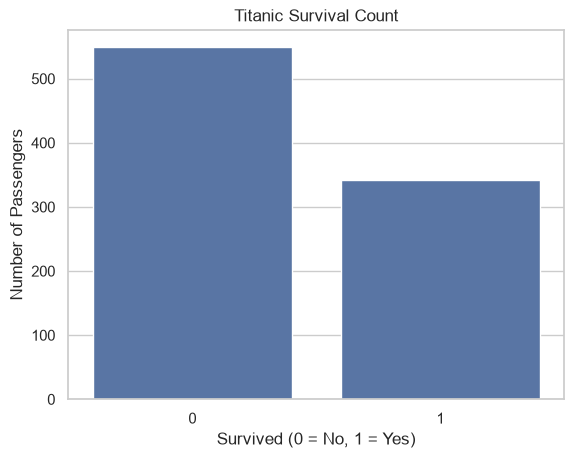

In [26]:
if "Survived" in df.columns:
    sns.countplot(data=df, x="Survived")
    plt.title("Titanic Survival Count")
    plt.xlabel("Survived (0 = No, 1 = Yes)")
    plt.ylabel("Number of Passengers")
    plt.show()

COMPARE SURVIVAL BY GENDER

Survival Rate by Gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


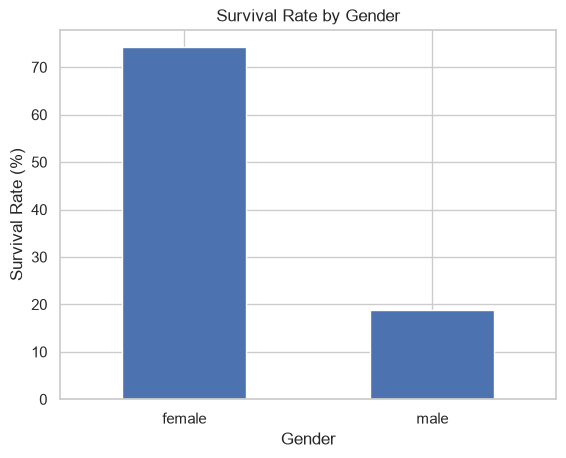

In [27]:
if {"Sex", "Survived"}.issubset(df.columns):
    gender_survival = df.groupby("Sex")["Survived"].mean() * 100

    print("Survival Rate by Gender (%):")
    print(gender_survival.round(2))

    gender_survival.plot(kind="bar")
    plt.title("Survival Rate by Gender")
    plt.xlabel("Gender")
    plt.ylabel("Survival Rate (%)")
    plt.xticks(rotation=0)
    plt.show()

COMPARE SURVIVAL BY PASSENGER CLASS

Survival Rate by Passenger Class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


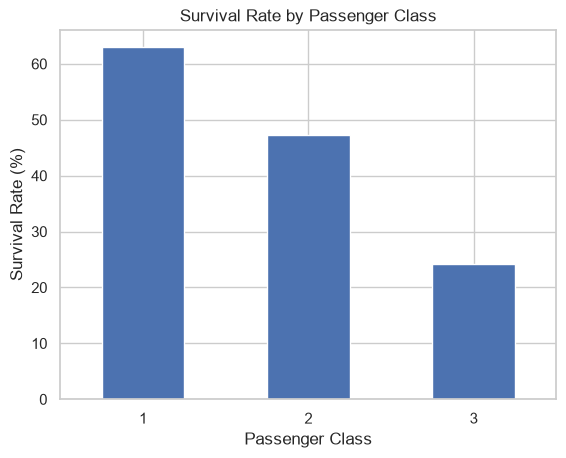

In [28]:
if {"Pclass", "Survived"}.issubset(df.columns):
    class_survival = df.groupby("Pclass")["Survived"].mean() * 100

    print("Survival Rate by Passenger Class (%):")
    print(class_survival.round(2))

    class_survival.plot(kind="bar")
    plt.title("Survival Rate by Passenger Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Survival Rate (%)")
    plt.xticks(rotation=0)
    plt.show()

ANALYZE AGE DISTRIBUTION

Average Age: 29.36
Median Age: 28.0


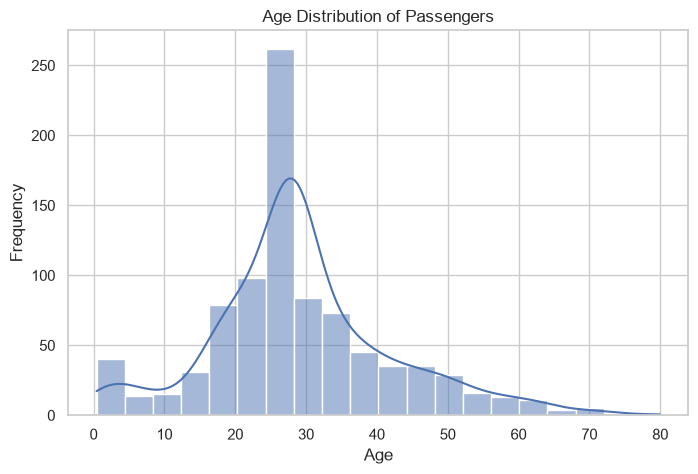

In [29]:
if "Age" in df.columns:
    print("Average Age:", round(df["Age"].mean(), 2))
    print("Median Age:", round(df["Age"].median(), 2))

    plt.figure(figsize=(8, 5))
    sns.histplot(df["Age"].dropna(), bins=20, kde=True)
    plt.title("Age Distribution of Passengers")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.show()

ANALYZE PASSENGER FARES

Average Fare: 32.2
Median Fare: 14.45


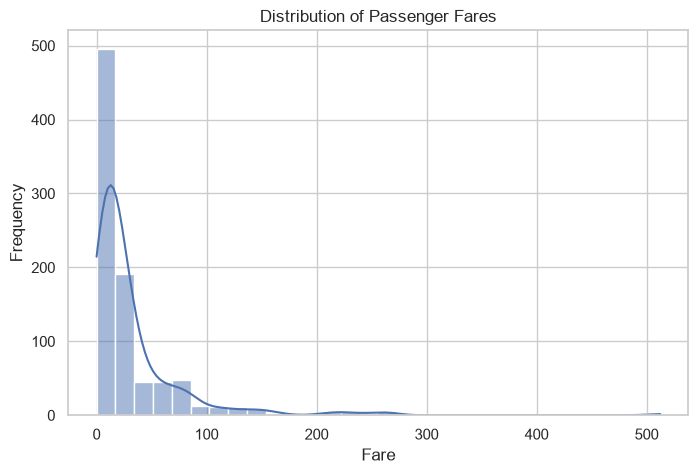

In [30]:
if "Fare" in df.columns:
    print("Average Fare:", round(df["Fare"].mean(), 2))
    print("Median Fare:", round(df["Fare"].median(), 2))

    plt.figure(figsize=(8, 5))
    sns.histplot(df["Fare"].dropna(), bins=30, kde=True)
    plt.title("Distribution of Passenger Fares")
    plt.xlabel("Fare")
    plt.ylabel("Frequency")
    plt.show()

CORRELATION BETWEEN NUMERICAL COLUMN

             PassengerId  Survived  Pclass   Age  SibSp  Parch  Fare
PassengerId         1.00     -0.01   -0.04  0.03  -0.06  -0.00  0.01
Survived           -0.01      1.00   -0.34 -0.06  -0.04   0.08  0.26
Pclass             -0.04     -0.34    1.00 -0.34   0.08   0.02 -0.55
Age                 0.03     -0.06   -0.34  1.00  -0.23  -0.17  0.10
SibSp              -0.06     -0.04    0.08 -0.23   1.00   0.41  0.16
Parch              -0.00      0.08    0.02 -0.17   0.41   1.00  0.22
Fare                0.01      0.26   -0.55  0.10   0.16   0.22  1.00


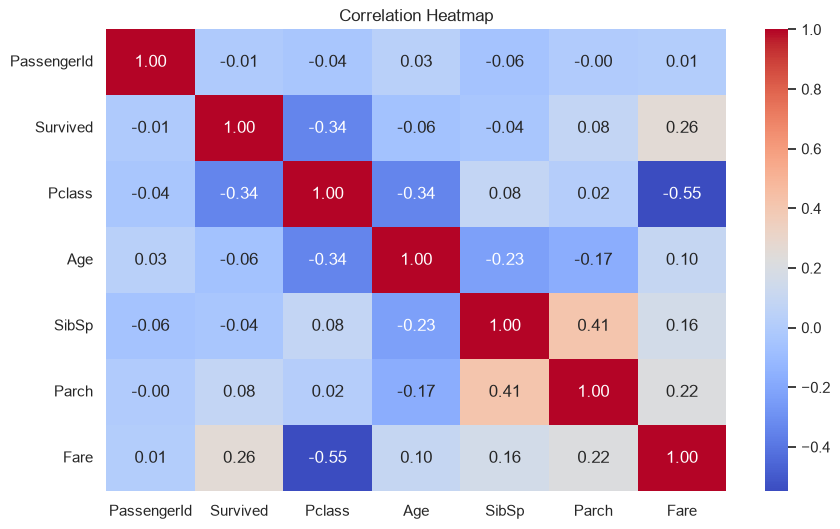

In [31]:
correlation = numeric_df.corr()

print(correlation.round(2))

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

COMPARE AVERAGE FARE BY CLASS

Average Fare by Passenger Class:
Pclass
1    84.15
2    20.66
3    13.68
Name: Fare, dtype: float64


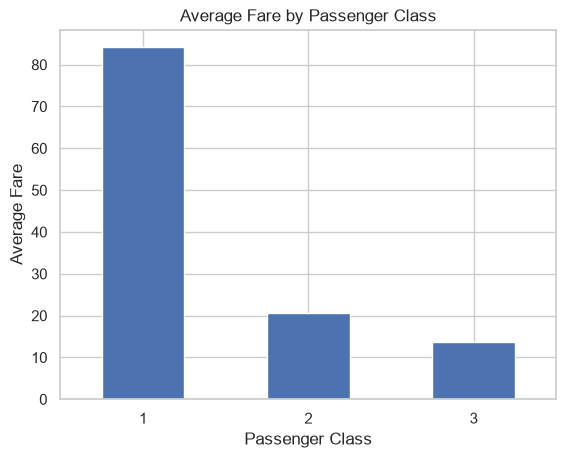

In [32]:
if {"Pclass", "Fare"}.issubset(df.columns):
    fare_by_class = df.groupby("Pclass")["Fare"].mean()

    print("Average Fare by Passenger Class:")
    print(fare_by_class.round(2))

    fare_by_class.plot(kind="bar")
    plt.title("Average Fare by Passenger Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Average Fare")
    plt.xticks(rotation=0)
    plt.show()

AUTOMATICALLY GENERATE IMPORTANT FINDING

In [33]:
print("IMPORTANT FINDINGS")

if {"Sex", "Survived"}.issubset(df.columns):
    gender_rates = df.groupby("Sex")["Survived"].mean() * 100
    print("\n1. Survival Rate by Gender:")
    print(gender_rates.round(2))

    if len(gender_rates) >= 2:
        print("Higher survival rate:", gender_rates.idxmax())

if {"Pclass", "Survived"}.issubset(df.columns):
    class_rates = df.groupby("Pclass")["Survived"].mean() * 100
    print("\n2. Survival Rate by Passenger Class:")
    print(class_rates.round(2))
    print("Class with highest survival rate:", class_rates.idxmax())

if "Age" in df.columns:
    print("\n3. Average Passenger Age:", round(df["Age"].mean(), 2))

if "Fare" in df.columns:
    print("\n4. Highest Ticket Fare:", df["Fare"].max())

IMPORTANT FINDINGS

1. Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64
Higher survival rate: female

2. Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64
Class with highest survival rate: 1

3. Average Passenger Age: 29.36

4. Highest Ticket Fare: 512.3292


## Conclusion

In this project, I analyzed the Titanic dataset using Python, Pandas, and NumPy. I calculated descriptive statistics, identified maximum and minimum values, compared passenger groups, examined survival rates, and explored relationships between numerical variables.

Visualizations helped make the results easier to understand.

**Key Findings:**
1. Compared survival rates between male and female passengers.
2. Identified differences in survival rates across passenger classes.
3. Examined the distribution of passenger ages and ticket fares.
4. Investigated correlations between numerical variables.

This analysis demonstrates how Python can be used to extract meaningful insights from real-world data.